# Walmart Weekly Sales Analysis

## Problem Statement

A retail store that has multiple outlets across the country is facing issues in managing the inventory to match the demand with respect to supply.

### Dataset Information

The `walmart.csv` dataset contains **6435 rows and 8 columns**.

| Feature Name | Description |
|---|---|
| `Store` | Store number |
| `Date` | Week of sales |
| `Weekly_Sales` | Sales for the given store in that week |
| `Holiday_Flag` | Indicates if it is a holiday week |
| `Temperature` | Temperature on the day of the sale |
| `Fuel_Price` | Cost of fuel in the region |
| `CPI` | Consumer Price Index |
| `Unemployment` | Unemployment Rate |

---

## Objective

Perform **statistical analysis, Exploratory Data Analysis (EDA), outlier analysis, and handle missing values** to gain insights into the following:

### 1. Unemployment and Weekly Sales
- Are the weekly sales affected by the unemployment rate?
- If yes, which stores are suffering the most?

### 2. Seasonal Trends
- Do the weekly sales show a seasonal trend?
- If yes, when does the seasonal trend occur and what could be the reason?

### 3. Temperature and Weekly Sales
- Does temperature affect the weekly sales in any manner?

### 4. Consumer Price Index and Weekly Sales
- How is the Consumer Price Index affecting the weekly sales of various stores?

### 5. Store Performance
- Perform a statistical analysis of the stores according to the historical data.

### 6. Best and Worst Performing Stores
- Identify the worst-performing store.
- Determine how significant the difference is between the highest and lowest performing stores.

---

# Data Dictionary

| Column | Meaning |
|---|---|
| `Store` | Store number / identifier of the store |
| `Date` | Week of sales |
| `Weekly_Sales` | Sales generated by the store during that week |
| `Holiday_Flag` | Indicates whether the week is a holiday week (1 = Holiday, 0 = Non-Holiday) |
| `Temperature` | Temperature recorded during the week |
| `Fuel_Price` | Fuel price in the region during that week |
| `CPI` | Consumer Price Index for the region during that week |
| `Unemployment` | Unemployment rate in the region during that week |

---

## Main Variable of Interest

`Weekly_Sales`

The primary goal of the analysis is to understand the patterns in weekly sales and investigate how different factors such as **time, holidays, temperature, CPI, unemployment, and store differences** are associated with weekly sales.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv("/content/Walmart DataSet.csv")
df

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...,...
6430,45,28-09-2012,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,05-10-2012,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,12-10-2012,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,19-10-2012,718125.53,0,56.47,3.969,192.330854,8.667


In [ ]:
df['Date']=pd.to_datetime(df['Date'],format="%d-%m-%Y")
#Converting object to datetime type for the date column

In [ ]:
#set date as the index for the data frame
df.set_index("Date",inplace=True)

In [ ]:
# There are about 45 different stores in this dataset. Lets select the any store id from 1-45
a= int(input("Enter the store id:"))
store = df[df.Store == a]
sales = store['Weekly_Sales']
sales
#Sales is now in the required time series format, index -> date and values as the single col

Enter the store id:7


,Weekly_Sales
Date,
2010-02-05,496725.44
2010-02-12,524104.92
2010-02-19,506760.54
2010-02-26,496083.24
2010-03-05,491419.55
...,...
2012-09-28,525545.76
2012-10-05,505830.56
2012-10-12,503463.93


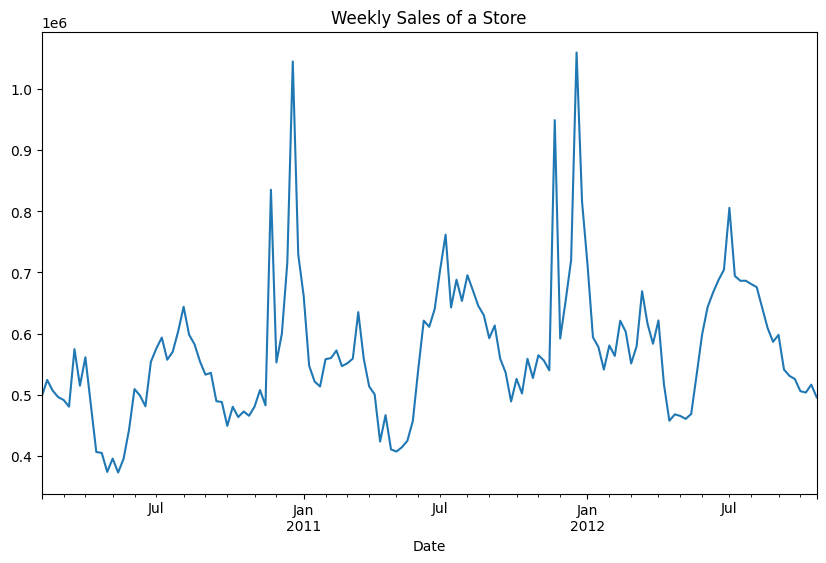

In [ ]:
sales.plot(figsize=(10,6), title= 'Weekly Sales of a Store', fontsize=10)
plt.show()

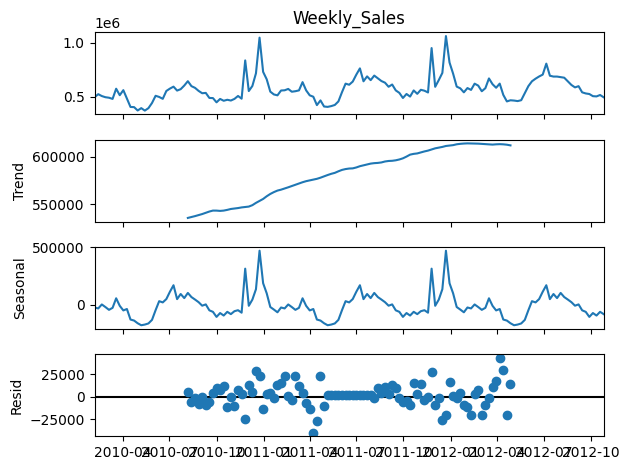

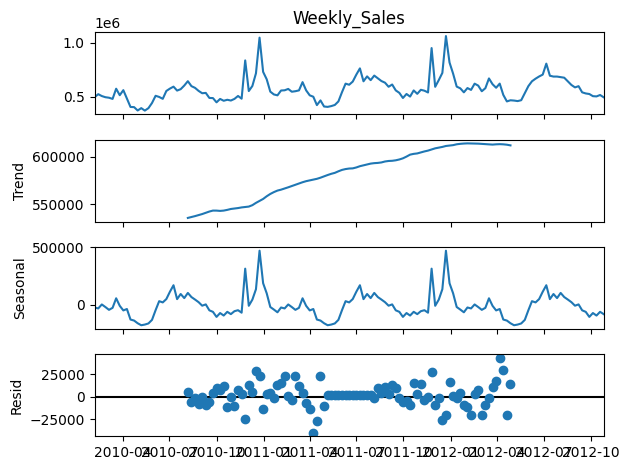

In [ ]:
#seeing the seasonal decomposition
from statsmodels.tsa.seasonal import seasonal_decompose
seasonal_decompose(sales,period=52).plot()

### Seasonal Decomposition — Observation

- **Observed:** Weekly sales show considerable fluctuations with several sharp peaks.
- **Trend:** Sales show a gradual increasing trend over the period.
- **Seasonal:** A clear repeating pattern of peaks and dips can be observed at regular intervals.
- **Residual:** Residual values fluctuate around zero, with some larger positive and negative deviations.

**Overall:** The decomposition shows an increasing trend along with a clear repeating seasonal pattern in weekly sales.

In [ ]:
#Let's compare the sales of different stores, suppose with store 10
store10 = df[df.Store == 10]
sales10 = store10['Weekly_Sales']
sales10

,Weekly_Sales
Date,
2010-02-05,2193048.75
2010-02-12,2176028.52
2010-02-19,2113432.58
2010-02-26,2006774.96
2010-03-05,1987090.09
...,...
2012-09-28,1694862.41
2012-10-05,1758971.38
2012-10-12,1713889.11


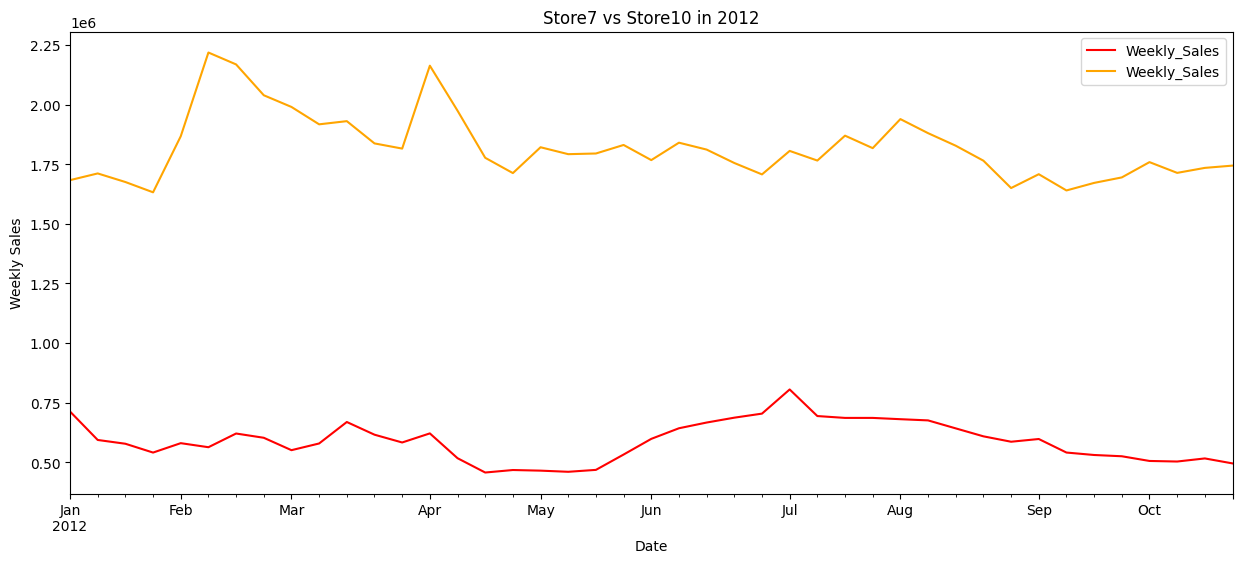

In [ ]:
#Plot the graphs for both the stores side to side to compare their performance
sales['2012'].plot(figsize=(15, 6),legend=True, color = 'red')
sales10['2012'].plot(figsize=(15, 6), legend=True, color = 'orange')
plt.ylabel('Weekly Sales')
plt.title('Store7 vs Store10 in 2012')
plt.show()

In [ ]:
#From the above, it is clear that different stores have strikingly different patterns
# we used sales['year'] as date is now the index for the pandas series sales
# date-based row selection because sales has DatetimeIndex

In [ ]:
#perform the ADF test for sales to get d value
from statsmodels.tsa.stattools import adfuller

result = adfuller(sales)

print("p-value:", result[1])

p-value: 0.0002170071890711771


/tmp/ipykernel_15593/3569437595.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(sales)


In [ ]:
#p-value -> 0.0002 => stationary and hence d=0

In [ ]:
seasonal_diff = sales.diff(52).dropna()

result = adfuller(seasonal_diff)

print("p-value:", result[1])
#seasonally not stationary => seasonal D=1

p-value: 0.161227913085625


/tmp/ipykernel_15593/3582496701.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(seasonal_diff)


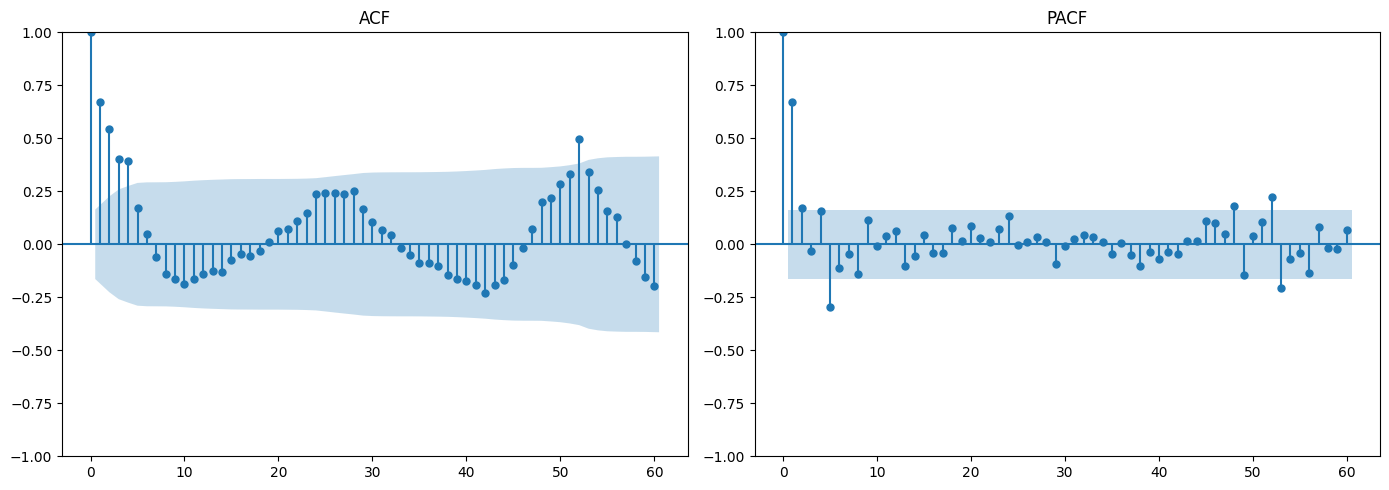

In [ ]:
# To find out the values of p, d, q

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ACF
plot_acf(sales, lags=60, ax=axes[0])
axes[0].set_title('ACF')

# PACF
plot_pacf(sales, lags=60, ax=axes[1])
axes[1].set_title('PACF')

plt.tight_layout()
plt.show()

In [ ]:
#ACF -> p preferred lags -> 1,2,3
#PACF -> q preferred lags -> 1,2,3
#Out of these, we choose the optimum using the AIC, BIC scores

In [ ]:
import statsmodels.api as sm
import itertools

# Non-seasonal parameters
p = range(1, 4)      # 1, 2, 3
d = [0]              # d = 0
q = range(1, 4)      # 1, 2, 3

# Seasonal parameters
P = range(0, 2)      # 0, 1
D = range(0, 2)      # 0, 1
Q = range(0, 2)      # 0, 1
s = 52                # yearly seasonality for weekly data

pdq = list(itertools.product(p, d, q))

seasonal_pdq = [
    (P_, D_, Q_, s)
    for P_ in P
    for D_ in D
    for Q_ in Q ]

order_aic_bic = []

for param in pdq:
    for seasonal_param in seasonal_pdq:
        try:
            model = sm.tsa.statespace.SARIMAX(
                sales,
                order=param,
                seasonal_order=seasonal_param,
                enforce_invertibility=False
            )

            results = model.fit(disp=False)

            order_aic_bic.append(
                (
                    param,
                    seasonal_param,
                    results.aic,
                    results.bic
                )
            )

        except:
            continue

order_df = pd.DataFrame(
    order_aic_bic,
    columns=['order', 'seasonal_order', 'aic', 'bic']
)

print("Number of models fitted:", len(order_df))

print("\nTop models by AIC:")
print(
    order_df
    .sort_values('aic')
    .reset_index(drop=True)
    .head(10)
)

print("\nTop models by BIC:")
print(
    order_df
    .sort_values('bic')
    .reset_index(drop=True)
    .head(10)
)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. A

Number of models fitted: 71

Top models by AIC:
       order seasonal_order          aic          bic
0  (1, 0, 2)  (1, 1, 1, 52)  2167.013959  2182.079116
1  (2, 0, 2)  (1, 1, 1, 52)  2169.693579  2187.269596
2  (1, 0, 3)  (1, 1, 1, 52)  2170.153162  2187.729178
3  (1, 0, 1)  (1, 1, 1, 52)  2170.949545  2183.503843
4  (2, 0, 3)  (1, 1, 1, 52)  2170.976175  2191.063051
5  (3, 0, 2)  (1, 1, 1, 52)  2171.428447  2191.515323
6  (2, 0, 2)  (1, 1, 0, 52)  2171.890325  2186.955482
7  (3, 0, 3)  (1, 1, 1, 52)  2172.745292  2195.343027
8  (1, 0, 2)  (0, 1, 1, 52)  2173.305748  2185.860045
9  (3, 0, 2)  (1, 1, 0, 52)  2173.339749  2190.915766

Top models by BIC:
       order seasonal_order          aic          bic
0  (1, 0, 2)  (1, 1, 1, 52)  2167.013959  2182.079116
1  (1, 0, 1)  (1, 1, 1, 52)  2170.949545  2183.503843
2  (1, 0, 1)  (1, 1, 0, 52)  2175.049653  2185.093091
3  (1, 0, 2)  (0, 1, 1, 52)  2173.305748  2185.860045
4  (2, 0, 2)  (1, 1, 0, 52)  2171.890325  2186.955482
5  (2, 0, 2)  

In [ ]:
#Training the model with optimum p and q values
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(sales,order=(1, 0, 2),seasonal_order=(1, 1, 1, 52))

model_fit = model.fit(disp=False)

print(model_fit.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


                                      SARIMAX Results                                       
Dep. Variable:                         Weekly_Sales   No. Observations:                  143
Model:             SARIMAX(1, 0, 2)x(1, 1, [1], 52)   Log Likelihood               -1077.504
Date:                              Mon, 05 Oct 2026   AIC                           2167.008
Time:                                      18:33:42   BIC                           2182.073
Sample:                                  02-05-2010   HQIC                          2173.086
                                       - 10-26-2012                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7242      0.102     -7.121      0.000      -0.923      -0.525
ma.L1          1.18

In [ ]:
#One-step forecasting, i.e., with all the data available till 27th july 2012 to predict next week
pred = results.get_prediction(
    start=pd.to_datetime('2012-07-27'),
    dynamic=False
)

pred_ci = pred.conf_int()

y_forecasted = pred.predicted_mean
y_truth = sales['2012-07-27':]

In [ ]:
#Calculating MSE for our trained model for one-step forecasting(non dynamic-> when the actual values
#are considered for further predictions and our predictions aren't fed again)
mse = ((y_forecasted - y_truth) ** 2).mean()

print("The Mean Squared Error of our forecasts is:", round(mse, 2))

The Mean Squared Error of our forecasts is: 1103036915.64


### Plotting Non-Dynamic Forecasting vs Actual Sales

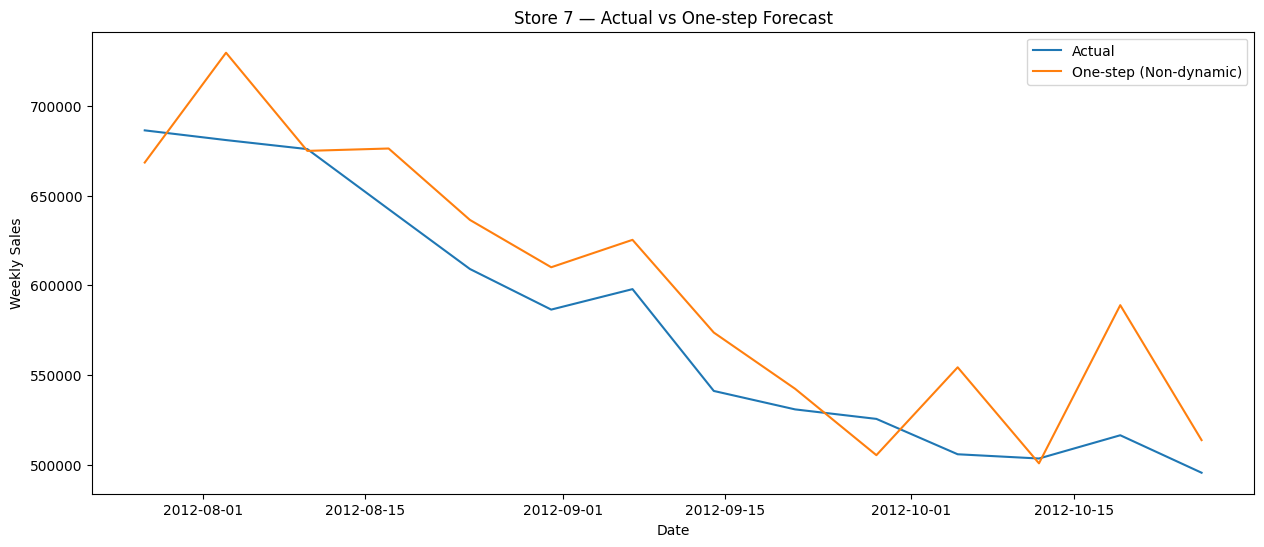

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(y_truth.index, y_truth, label='Actual')
plt.plot(y_forecasted.index, y_forecasted, label='One-step (Non-dynamic)')

plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.title(f'Store {a} — Actual vs One-step Forecast')
plt.legend()
plt.show()

In [ ]:
#Dynamic, one-step forecasting -> predicted values are used to further predict the next values
pred_dynamic = results.get_prediction(
    start=pd.to_datetime('2012-07-27'),
    dynamic=True
)

y_forecasted_dyn = pred_dynamic.predicted_mean

In [ ]:
#Calculating RMSE for our dynamic forecasting
rmse = np.sqrt(((y_forecasted_dyn - y_truth) ** 2).mean())

print(
    "The Root Mean Squared Error of our forecasts is:",
    round(rmse, 2)
)

The Root Mean Squared Error of our forecasts is: 38060.32


### Plotting Dynamic Forecasting vs Actual Sales

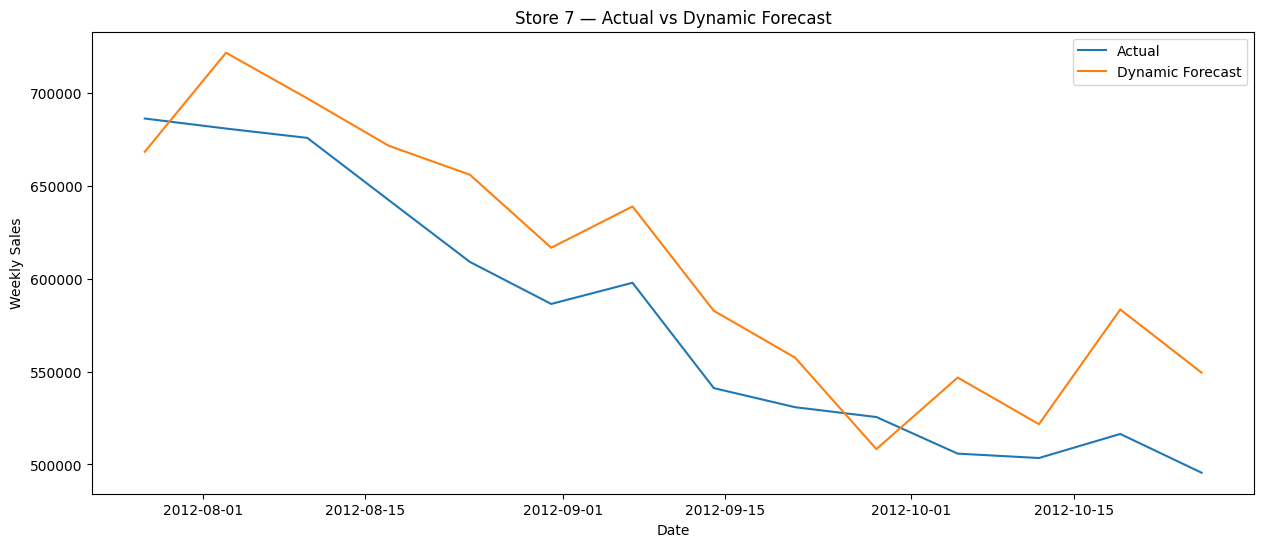

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(y_truth.index, y_truth, label='Actual')
plt.plot(y_forecasted_dyn.index, y_forecasted_dyn, label='Dynamic Forecast')

plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.title(f'Store {a} — Actual vs Dynamic Forecast')
plt.legend()
plt.show()

In [ ]:
#Residual calculation for our model
Residual = y_forecasted_dyn - y_truth

print("Residual for Store", a, np.abs(Residual).sum())

Residual for Store 7 385964.5755124854


### Predictions for the next 12 weeks:

In [ ]:
pred_uc = results.get_forecast(steps=12)

pred_ci = pred_uc.conf_int()

forecast = pred_uc.predicted_mean

print(forecast)

2012-11-02    5.892821e+05
2012-11-09    5.718744e+05
2012-11-16    5.668502e+05
2012-11-23    9.869940e+05
2012-11-30    6.175778e+05
2012-12-07    6.789019e+05
2012-12-14    7.468087e+05
2012-12-21    1.096623e+06
2012-12-28    8.506113e+05
2013-01-04    7.407350e+05
2013-01-11    6.180397e+05
2013-01-18    6.014390e+05
Freq: W-FRI, Name: predicted_mean, dtype: float64


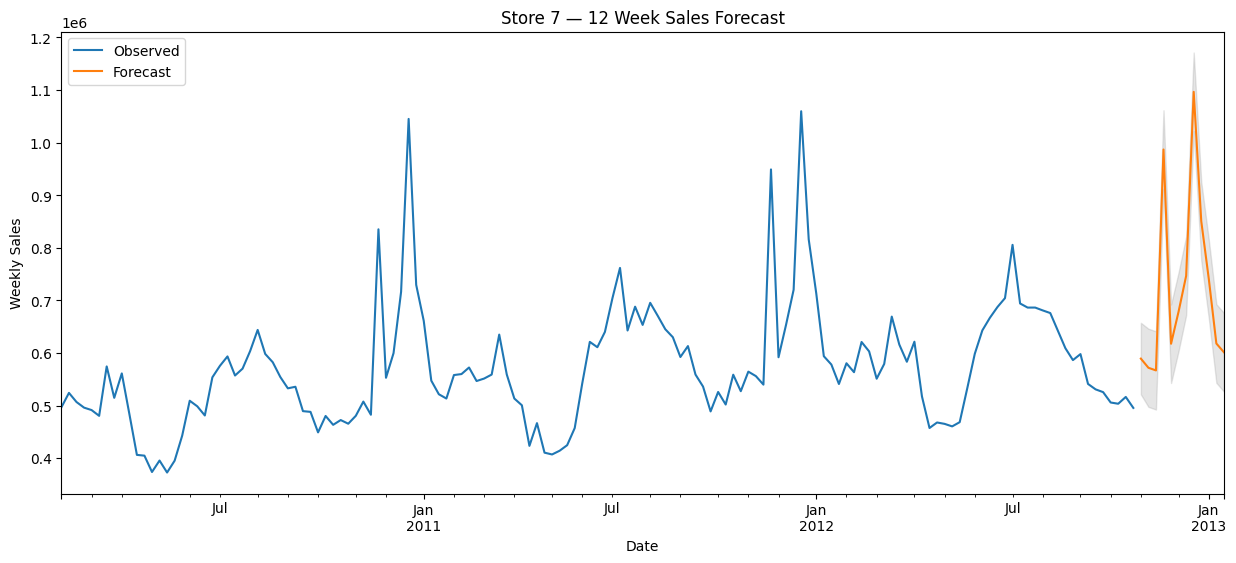

In [ ]:
ax = sales.plot(
    figsize=(15, 6),
    label='Observed'
)

forecast.plot(
    ax=ax,
    label='Forecast'
)

ax.fill_between(
    pred_ci.index,
    pred_ci.iloc[:, 0],
    pred_ci.iloc[:, 1],
    color='gray',
    alpha=0.2
)

plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.title(f'Store {a} — 12 Week Sales Forecast')
plt.legend()
plt.show()

### Part 2 — Conclusion

The SARIMAX model was used to forecast weekly sales for the selected store for the next 12 weeks. Seasonal decomposition and ACF/PACF analysis indicated a strong annual seasonal pattern in the weekly sales data, which was incorporated into the model using a seasonal period of 52 weeks.

The selected SARIMAX(1,0,2)(1,1,1,52) model provided a good fit for the selected store. For Store 7, the dynamic forecast achieved an RMSE of approximately 38,060, indicating relatively small forecasting errors compared with the scale of weekly sales.

The final 12-week forecast captures the observed seasonal behavior, including the expected year-end sales increase. The confidence intervals also show that forecast uncertainty increases further into the future.

Overall, the SARIMAX model provides a useful approach for forecasting weekly store-level sales while accounting for both temporal dependence and yearly seasonality.